In [12]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score   
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

In [6]:
df=pd.read_csv("pha_dataset_cleaned.csv")

In [7]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191



CASE 1: PHA CLASSIFICATION & IMBALANCE STUDY

In [ ]:
# 1. LOAD PREPROCESSED DATA
# ============================================================

if not os.path.exists("processed_data/X_train.csv"):
    raise FileNotFoundError(
        "Processed data not found! Run preprocessing.py first." )

X_train = pd.read_csv("processed_data/X_train.csv")

X_test = pd.read_csv("processed_data/X_test.csv")

y_train = pd.read_csv("processed_data/y_train.csv").values.ravel()

y_test = pd.read_csv("processed_data/y_test.csv").values.ravel()


print("\nTraining data shape:", X_train.shape)
print("Testing data shape :", X_test.shape)

print("\nOriginal training class distribution:")
print(pd.Series(y_train).value_counts())


Training data shape: (750879, 23)
Testing data shape : (187720, 23)

Original training class distribution:
0    749226
1      1653
Name: count, dtype: int64


# 2. HANDLE CLASS IMBALANCE
# ============================================================

# ------------------------------------------------------------
# SMOTE
# ------------------------------------------------------------
# IMPORTANT:
# SMOTE is applied ONLY to training data.
# Never apply SMOTE to test data.

In [ ]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train,y_train)

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())


After SMOTE:
0    749226
1    749226
Name: count, dtype: int64


In [15]:
# Calculate class weight for XGBoost
scale_pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()

print("Scale Pos Weight:", scale_pos_weight_val)

Scale Pos Weight: 453.2522686025408


In [10]:
#3. DEFINE MODELS


In [16]:
experiments = {

    # --------------------------------------------------------
    # LOGISTIC REGRESSION
    # --------------------------------------------------------

    "Logistic Regression (Baseline)": LogisticRegression(
        max_iter=1000,
        random_state=42),

    "Logistic Regression (Weighted)": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42),

    "Logistic Regression (SMOTE)": LogisticRegression(
        max_iter=1000,
        random_state=42 ),

   # RANDOM FOREST
    # --------------------------------------------------------

    "Random Forest (Baseline)": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1),

    "Random Forest (Weighted)": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=1),

    "Random Forest (SMOTE)": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1),


    # --------------------------------------------------------
    # XGBOOST
    # --------------------------------------------------------

    "XGBoost (Baseline)": XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1),

    "XGBoost (Weighted)": XGBClassifier(
        scale_pos_weight=scale_pos_weight_val,
        random_state=42,
        eval_metric="logloss",
        n_jobs=10),

    "XGBoost (SMOTE)": XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1)}

In [17]:
# 4. TRAIN AND EVALUATE
# ============================================================

results_list = []

trained_models = {}

for exp_name, model in experiments.items():

    print(f"\nRunning: {exp_name}")


Running: Logistic Regression (Baseline)

Running: Logistic Regression (Weighted)

Running: Logistic Regression (SMOTE)

Running: Random Forest (Baseline)

Running: Random Forest (Weighted)

Running: Random Forest (SMOTE)

Running: XGBoost (Baseline)

Running: XGBoost (Weighted)

Running: XGBoost (SMOTE)


In [18]:
# Decide training data
    # --------------------------------------------------------

if "SMOTE" in exp_name:

        X_train_used = X_train_smote
        y_train_used = y_train_smote

else:

        X_train_used = X_train
        y_train_used = y_train

In [19]:
 # Train model
    # --------------------------------------------------------

model.fit(X_train_used,y_train_used    )
trained_models[exp_name] = model


In [20]:
 # Prediction
    # --------------------------------------------------------

y_pred = model.predict(X_test )

y_pred_proba = model.predict_proba(X_test )[:, 1]

In [21]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(187720,))

In [22]:
  # PR-AUC
    # --------------------------------------------------------

precision_curve, recall_curve, _ = (precision_recall_curve(y_test,y_pred_proba))
pr_auc = auc(recall_curve,precision_curve)

In [23]:
 # ROC-AUC
    # --------------------------------------------------------

roc_auc = roc_auc_score(y_test,y_pred_proba)

In [24]:
 # Classification metrics
    # --------------------------------------------------------

accuracy = accuracy_score(y_test,y_pred) 

precision = precision_score(y_test,y_pred,zero_division=0)

recall = recall_score(y_test,y_pred,zero_division=0)

f1 = f1_score(y_test,y_pred,zero_division=0)


In [25]:
    # Store results
    # --------------------------------------------------------

results_list.append({

      "Experiment": exp_name,

        "Accuracy": round(accuracy,4),

        "PR-AUC": round(pr_auc, 4),    

        "ROC-AUC": round(roc_auc,4),

        "Precision": round(precision,4),    

        "Recall": round(recall,4),

        "F1-Score": round( f1,4 )})


In [26]:
# 5. CREATE RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(results_list)

# Sort by PR-AUC
results_df = results_df.sort_values(by="PR-AUC",ascending=False)

In [27]:
# 6. PRINT RESULTS
# ============================================================

print("\n")
print("======================================================================")
print("CASE 1 CLASSIFICATION RESULTS")
print("======================================================================")

print(
    results_df.to_string(index=False ))



CASE 1 CLASSIFICATION RESULTS
     Experiment  Accuracy  PR-AUC  ROC-AUC  Precision  Recall  F1-Score
XGBoost (SMOTE)    0.9899  0.3536   0.9959      0.164  0.8741    0.2762


In [28]:
# ============================================================
# 7. SAVE RESULTS
# ============================================================

os.makedirs("results", exist_ok=True)

results_df.to_csv("results/case1_classification_results.csv",index=False)

print("\n[SUCCESS] Results saved to:")

print("results/case1_classification_results.csv")



[SUCCESS] Results saved to:
results/case1_classification_results.csv


In [29]:
# 8. BEST MODEL
# ============================================================

best_experiment = results_df.iloc[0]["Experiment"]

best_pr_auc = results_df.iloc[0]["PR-AUC"]

print("\n==========================================")
print("BEST EXPERIMENT")
print("==========================================")

print("Model:", best_experiment)
print("PR-AUC:", best_pr_auc)


BEST EXPERIMENT
Model: XGBoost (SMOTE)
PR-AUC: 0.3536


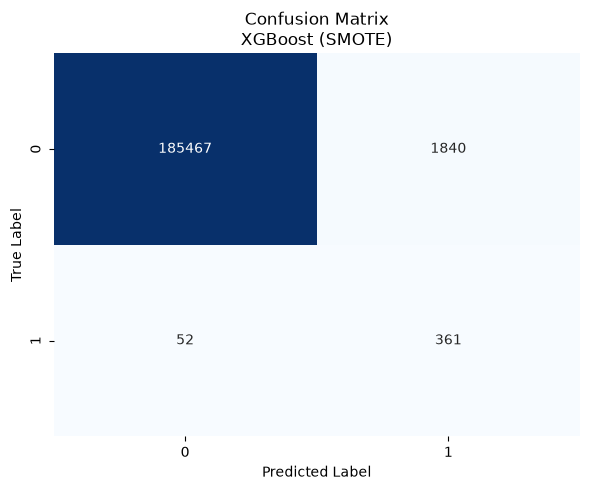

In [30]:
# 9. CONFUSION MATRIX FOR BEST MODEL
# ============================================================

best_model = trained_models[best_experiment]

best_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues", cbar=False)

plt.title(f"Confusion Matrix\n{best_experiment}")

plt.xlabel("Predicted Label")

plt.ylabel("True Label")

plt.tight_layout()

plt.show()



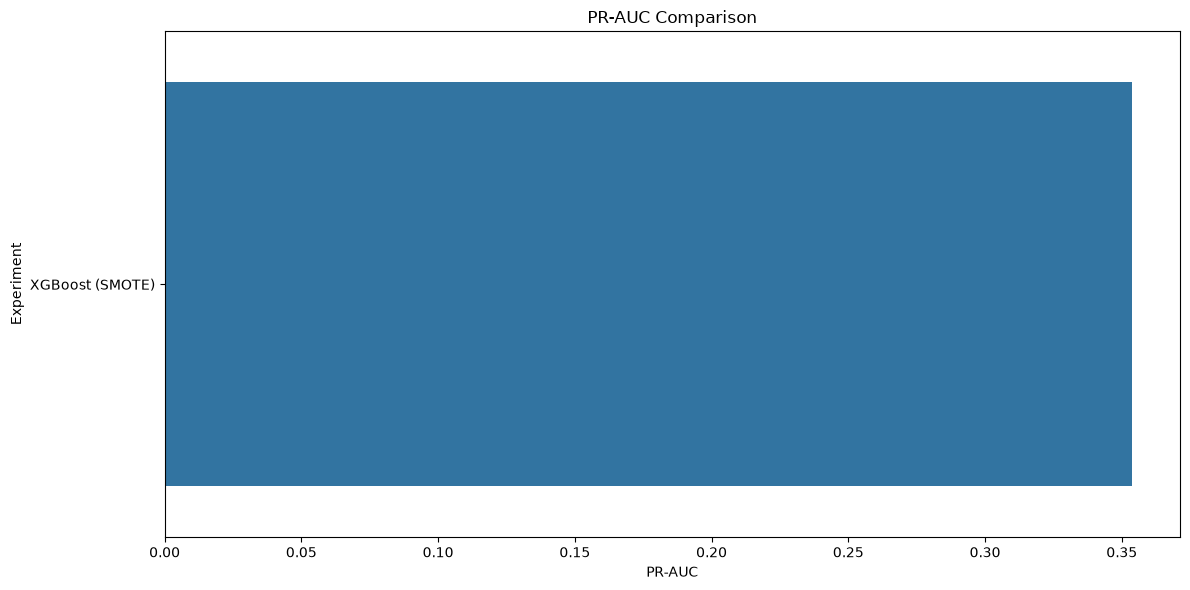


CASE 1 COMPLETED


In [32]:
# 10. MODEL COMPARISON - PR-AUC
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(data=results_df,x="PR-AUC",y="Experiment")

plt.title("PR-AUC Comparison")

plt.xlabel("PR-AUC")

plt.ylabel("Experiment")

plt.tight_layout()

plt.show()


print("\n==========================================")
print("CASE 1 COMPLETED")
print("==========================================")